# 05 — Data Storytelling: Menceritakan Dataset dengan Mudah

**Kenapa notebook ini ada?** Karena pekerjaan data analyst tidak berhenti di
menghitung angka — pekerjaan kita selesai ketika **orang lain paham dan memakainya**.

Notebook ini menunjukkan **cara bercerita dari dataset** yang sama, dengan bahasa
yang mudah dipahami siapa saja (termasuk orang non-teknis), lengkap dengan pola,
contoh naskah, dan grafik pendukung.

> ### Pola bercerita yang dipakai di sini: **Hook → Angka → Makna → Rekomendasi**

1. **Hook** — kalimat pembuka yang membuat orang mau mendengarkan
2. **Angka** — 1–2 bukti (bukan seluruh tabel)
3. **Makna** — terjemahan angka ke bahasa manusia
4. **Rekomendasi** — apa yang bisa dilakukan pembaca dengan temuan ini

## 1. Persiapan

Grafik di notebook ini memakai data yang **sudah** bersih (`spotify_clean.joblib`
dari notebook 03), jadi storyteller tidak perlu pusing ke urusan cleaning — cukup
fokus pada ceritanya.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

BIRU, ORANYE, HIJAU, MERAH, ABU = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#898781"

data = joblib.load("../data/clean/spotify_clean.joblib")
songs, genres_long, artists = data["songs"], data["genres_long"], data["artists"]
print(f"{len(songs)} lagu, {len(artists)} artis, tahun {songs['year'].min()}-{songs['year'].max()}")

1926 lagu, 835 artis, tahun 1998-2020


## 2. Cerita #1 — "Tidak ada formula ajaib untuk bikin lagu populer"

**Hook:** setiap orang punya teori sendiri soal "kenapa lagu hits?" — suaranya keras?
kencang? banyak bicara?

**Angka:** kita uji langsung. Di bawah ini korelasi (Spearman) tiap fitur audio
dengan popularity. Yang terkuat pun cuma **0.07** — praktis nol.

**Makna:** membuat lagu populer bukan soal *sound*, tapi soal faktor di luar audio
(penyanyi, promosi, momen rilis, viral di medsos).

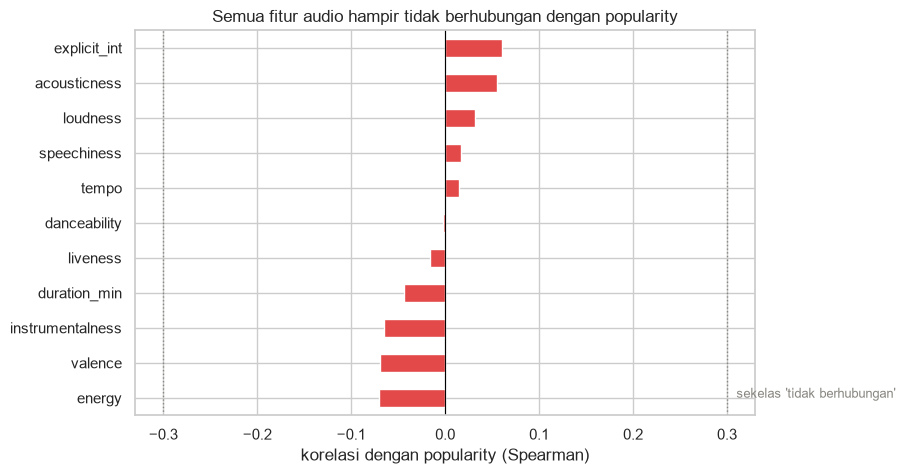

Korelasi terkuat dengan popularity:
energy              0.070
valence             0.070
instrumentalness    0.066


In [2]:
kolom_angka = ["popularity", "danceability", "energy", "valence", "loudness", "tempo",
               "duration_min", "acousticness", "speechiness", "instrumentalness",
               "liveness", "explicit_int"]
korelasi_pop = songs[kolom_angka].corr(method="spearman")["popularity"].drop("popularity").sort_values()

plt.figure(figsize=(8, 5))
colors = [MERAH if abs(v) < 0.1 else BIRU for v in korelasi_pop]
korelasi_pop.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.axvline(0.3, color=ABU, linestyle=":", linewidth=1)
plt.axvline(-0.3, color=ABU, linestyle=":", linewidth=1)
plt.title("Semua fitur audio hampir tidak berhubungan dengan popularity")
plt.xlabel("korelasi dengan popularity (Spearman)")
plt.text(0.31, 0, "sekelas 'tidak berhubungan'", fontsize=9, color=ABU)
plt.show()

print("Korelasi terkuat dengan popularity:")
print(korelasi_pop.abs().sort_values(ascending=False).head(3).round(3).to_string())

**Rekomendasi untuk cerita ini:** kalau kamu musisi/penyanyi independen, jangan
habiskan semua energi mengejar "sound hits". Populer tetap butuh distribusi,
timing, dan konsistensi.

## 3. Cerita #2 — "Lagu-lagu populer makin pendek dan makin keras"

**Hook:** kalau kamu merasa lagu-lagu sekarang "lebih pendek" dari dulu — itu
bukan nostalgia, itu terlihat dari data.

**Angka:** dari 1990-an ke 2010-an, durasi rata-rata turun, loudness naik, dan
lagu makin sedikit yang akustik.

**Makna:** ini mencerminkan era streaming (model bisnis baru + perhatian pendek),
bukan selera musisi yang tiba-tiba berubah.

        n_lagu  loudness  energy  acousticness  duration_min
decade                                                      
1990an      39    -6.073   0.731         0.149         4.207
2000an     904    -5.543   0.731         0.124         3.986
2010an     980    -5.459   0.713         0.132         3.634
2020an       3    -4.925   0.785         0.147         3.620


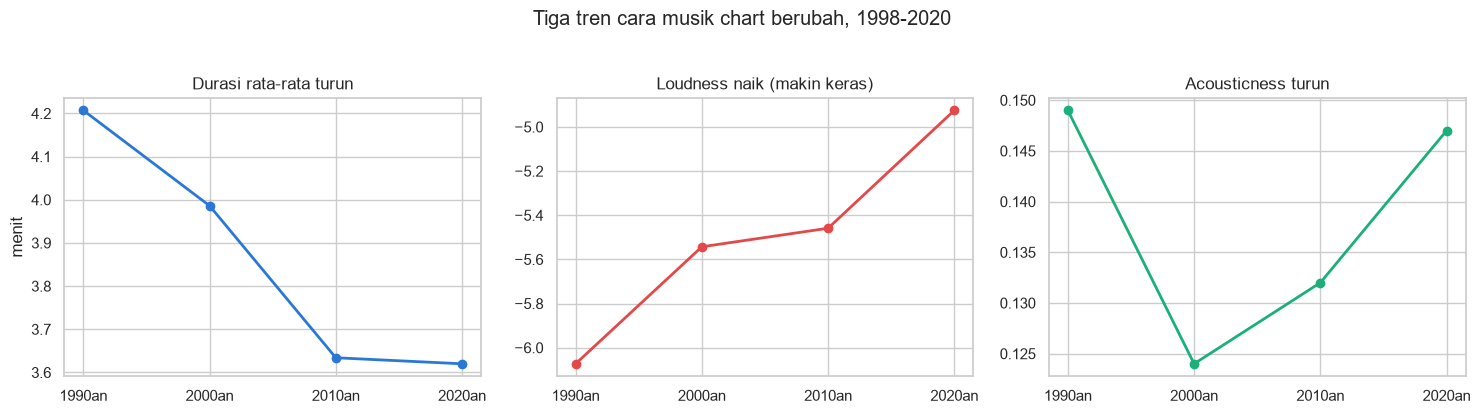

In [3]:
tren = songs.groupby("decade", observed=True).agg(
    n_lagu=("song", "count"),
    loudness=("loudness", "mean"),
    energy=("energy", "mean"),
    acousticness=("acousticness", "mean"),
    duration_min=("duration_min", "mean"),
).round(3)
print(tren.to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(tren.index.astype(str), tren["duration_min"], marker="o", color=BIRU, linewidth=2)
axes[0].set_title("Durasi rata-rata turun")
axes[0].set_ylabel("menit")

axes[1].plot(tren.index.astype(str), tren["loudness"], marker="o", color=MERAH, linewidth=2)
axes[1].set_title("Loudness naik (makin keras)")

axes[2].plot(tren.index.astype(str), tren["acousticness"], marker="o", color=HIJAU, linewidth=2)
axes[2].set_title("Acousticness turun")

for ax in axes:
    ax.set_xlabel("")
plt.suptitle("Tiga tren cara musik chart berubah, 1998-2020", y=1.03)
plt.tight_layout()
plt.show()

**Rekomendasi untuk cerita ini:** kalau kamu membuat mixtape/playlist tematik
per dekade, gunakan fitur durasi/loudness sebagai penanda era — bukan hanya tahun.

## 4. Cerita #3 — "Musik populer itu mayoritas bahagia dan energik"

**Hook:** pastikan musik populer itu "sedih-sedihan"? Coba lihat kuadran ini.

**Angka:** 57% lagu berada di kuadran **Bahagia & bersemangat** (valence dan energy
di atas 0.5), dan hanya 2.7% yang tenang.

**Makna:** chart pop memang condong ke lagu yang membuat orang bergerak — padahal
penonton identik dengan "lagu galau", jumlahnya jauh lebih sedikit.

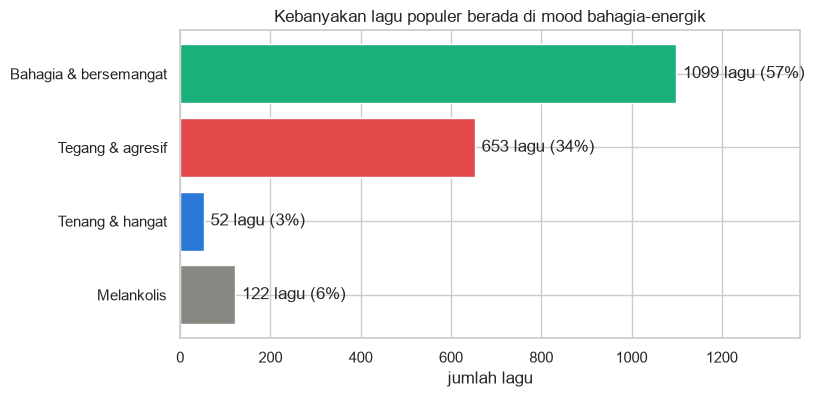

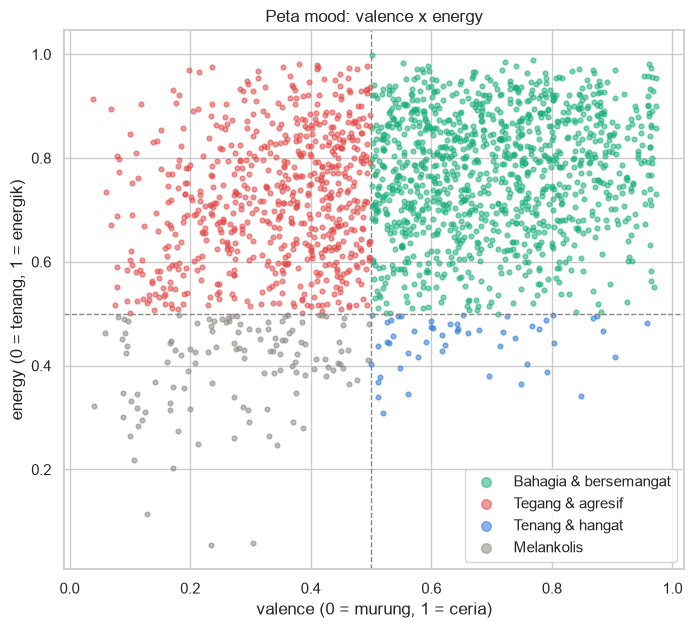

In [4]:
MOODS = ["Bahagia & bersemangat", "Tegang & agresif", "Tenang & hangat", "Melankolis"]
WARNA = {"Bahagia & bersemangat": HIJAU, "Tegang & agresif": MERAH,
         "Tenang & hangat": BIRU, "Melankolis": ABU}

hitung = songs["mood"].value_counts().reindex(MOODS)
plt.figure(figsize=(8, 4))
plt.barh(hitung.index[::-1], hitung.values[::-1],
         color=[WARNA[m] for m in hitung.index[::-1]])
for i, (mood, n) in enumerate(zip(hitung.index[::-1], hitung.values[::-1])):
    plt.text(n + 15, i, f"{n} lagu ({n/len(songs):.0%})", va="center")
plt.title("Kebanyakan lagu populer berada di mood bahagia-energik")
plt.xlabel("jumlah lagu")
plt.xlim(0, hitung.max() * 1.25)
plt.show()

plt.figure(figsize=(8, 7))
for mood in MOODS:
    sub = songs[songs["mood"] == mood]
    plt.scatter(sub["valence"], sub["energy"], s=12, alpha=0.55, color=WARNA[mood], label=mood)
plt.axhline(0.5, color=ABU, linestyle="--", linewidth=1)
plt.axvline(0.5, color=ABU, linestyle="--", linewidth=1)
plt.xlabel("valence (0 = murung, 1 = ceria)")
plt.ylabel("energy (0 = tenang, 1 = energik)")
plt.title("Peta mood: valence x energy")
plt.legend(markerscale=2)
plt.show()

**Rekomendasi untuk cerita ini:** kalau kamu membuat playlist, kuadran mood adalah
cara cepat memilahnya — "Bahagia & bersemangat" untuk workout/pagi hari,
"Melankolis" untuk malam, dan seterusnya.

## 5. Contoh naskah 30 detik (untuk presentasi atau README)

> "Kami meneliti **1.926 lagu populer dari 835 artis** (1998–2020). Tiga temuan
> utama. **Pertama**, nggak ada 'formula ajaib': dari 11 fitur audio, yang paling
> dekat kaitannya dengan popularity cuma **0.07** — praktis nol; yang membuat lagu
> populer adalah faktor di luar suara. **Kedua**, musik chart makin **pendek dan
> keras** seiring waktu, sejalan dengan kebiasaan streaming. **Ketiga**, 57% lagu
> bernuansa **bahagia-energik** — musik pop memang didominasi suara yang membuat
> orang bergerak. Semua temuan ini bisa dicek sendiri di dashboard Streamlit
> project ini, lengkap dengan filter per genre dan per dekade."

Coba baca naskah itu keras-keras sambil menghitung waktunya. Kalau bisa selesai
dalam 30 detik dan temanmu bisa mengulang intinya, kamu sudah menguasai
storytelling data dasar.

## 6. Hubungan insight dengan dashboard

Orang tidak percaya cerita tanpa bisa memverikasi sendiri. Setiap cerita di atas
punya "rumah" di dashboard (`app/app.py`):

| Cerita | Cek di dashboard |
|---|---|
| #1 Tidak ada formula ajaib | Tab **Korelasi** — heatmap & pasangan terkuat |
| #2 Lagu makin pendek/keras | Tab **Ringkasan** — lagu per tahun (trend) |
| #3 Mood didominasi bahagia-energik | Tab **Ringkasan** — sebaran mood |
| Detail per genre (pop vs hip hop) | Tab **Genre & audio** — pilih genre di sidebar |

**Aturan emas storytelling data:** setiap angka yang kamu sebut di presentasi harus
bisa diklik orang lain sampai ke datanya.

## 7. Ringkasan: 5 langkah storytelling yang bisa kamu pakai lagi

1. **Tentukan 1 pesan utama** — bukan 10 temuan; 1 saja yang paling penting.
2. **Susun dengan pola Hook → Angka → Makna → Rekomendasi.**
3. **Pilih 1–2 grafik terbaik** sebagai bukti (bukan semua grafik).
4. **Sebutkan keterbatasan** dengan jujur (mis. 121 lagu tanpa data popularity) —
   justru meningkatkan kredibilitas.
5. **Arahkan ke dashboard** supaya pembaca bisa memeriksa sendiri.

> "Data bisa membuat angka terdengar masuk akal. Storytelling membuat angka
> terdengar **masuk akal untuk dijalankan**.